Observe as opções:
          (1) Temperatura média de cada dia.
          (2) Guardar uma tabela meteorológica num ficheiro de texto.
          (3) Carregar uma tabela meteorológica de um ficheiro de texto.
          (4) Temperatura mínima mais baixa registada na tabela.
          (5) Amplitude térmica de cada dia.
          (6) Dia em que a precipitação registada teve o seu valor máximo e respetivo valor.
          (7) Dias em que a precipitação foi superior a um limite 'p'.
          (8) Maior número consecutivo de dias com precipitação abaixo de um limite 'p'.
          (9) Gráficos correspondentes aos valores de temperatura máxima, temperatura mínima e pluviosidade.
          
[((2022, 1, 20), 9.0), ((2022, 1, 21), 7.0), ((2022, 1, 22), 12.0)]
Observe as opções:
          (1) Temperatura média de cada dia.
          (2) Guardar uma tabela meteorológica num ficheiro de texto.
          (3) Carregar uma tabela meteorológica de um ficheiro de texto.
          (4) Temperatura mínima ma

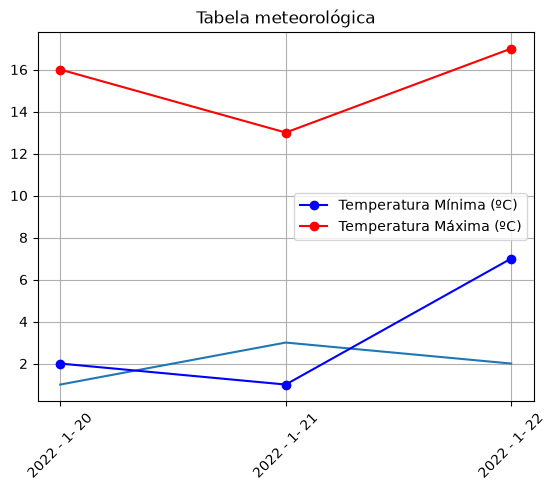

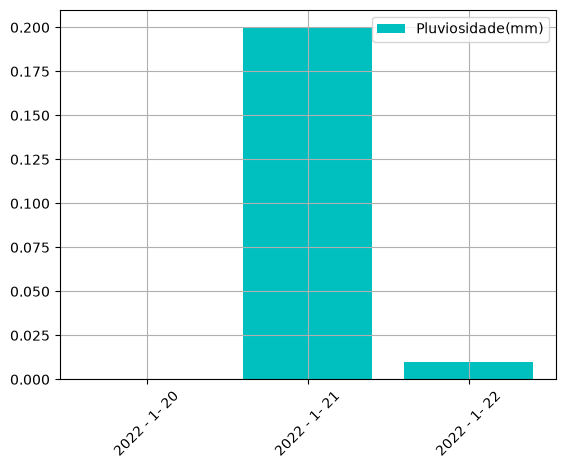

Observe as opções:
          (1) Temperatura média de cada dia.
          (2) Guardar uma tabela meteorológica num ficheiro de texto.
          (3) Carregar uma tabela meteorológica de um ficheiro de texto.
          (4) Temperatura mínima mais baixa registada na tabela.
          (5) Amplitude térmica de cada dia.
          (6) Dia em que a precipitação registada teve o seu valor máximo e respetivo valor.
          (7) Dias em que a precipitação foi superior a um limite 'p'.
          (8) Maior número consecutivo de dias com precipitação abaixo de um limite 'p'.
          (9) Gráficos correspondentes aos valores de temperatura máxima, temperatura mínima e pluviosidade.
          
Observe as opções:
          (1) Temperatura média de cada dia.
          (2) Guardar uma tabela meteorológica num ficheiro de texto.
          (3) Carregar uma tabela meteorológica de um ficheiro de texto.
          (4) Temperatura mínima mais baixa registada na tabela.
          (5) Amplitude térmica de cad

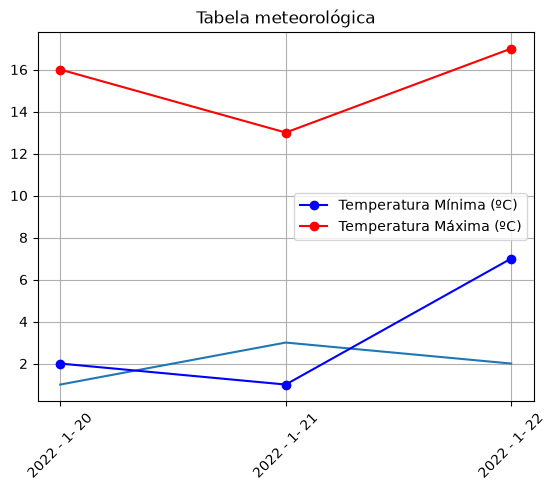

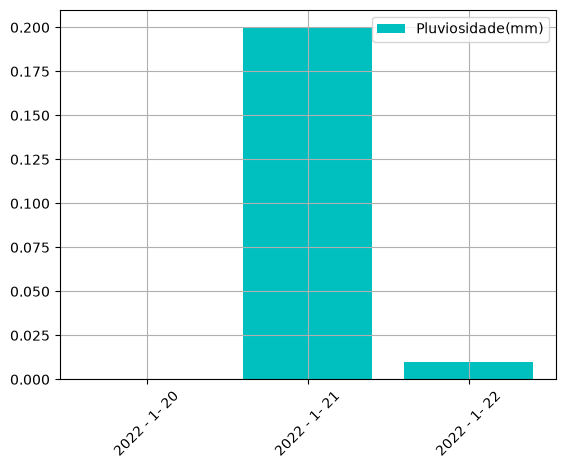

Observe as opções:
          (1) Temperatura média de cada dia.
          (2) Guardar uma tabela meteorológica num ficheiro de texto.
          (3) Carregar uma tabela meteorológica de um ficheiro de texto.
          (4) Temperatura mínima mais baixa registada na tabela.
          (5) Amplitude térmica de cada dia.
          (6) Dia em que a precipitação registada teve o seu valor máximo e respetivo valor.
          (7) Dias em que a precipitação foi superior a um limite 'p'.
          (8) Maior número consecutivo de dias com precipitação abaixo de um limite 'p'.
          (9) Gráficos correspondentes aos valores de temperatura máxima, temperatura mínima e pluviosidade.
          
Sair da aplicação.


In [3]:
# TabMeteo = [(Data,TempMin,TempMax,Precipitacao)]
    # Data = (Int,Int,Int)
    # TempMin = Float
    # TempMax = Float
    # Precipitacao = Float

tabMeteo1 = [((2022,1,20), 2, 16, 0),((2022,1,21), 1, 13, 0.2), ((2022,1,22), 7, 17, 0.01)]

def medias(tabMeteo):
    res = []
    
    for data, tmin, tmax, prec in tabMeteo:
        media= (tmax + tmin) / 2
        res.append((data, media))
    return res


def guardaTabMeteo(t, fnome):
    f= open(fnome, "w")
    for data, tmin, tmax, prec in t:
        ano, mes, dia= data
        f.write(f"{ano}-{mes}-{dia}; {tmin}; {tmax}; {prec}\n")
    f.close()
    return

def carregaTabMeteo(fnome):
    res = []
    file= open(fnome, "r")
    for line in file:
        #line=line[:-1]
        line= line.strip()
        campos= line.split(";")
        data, tmin, tmax, prec= campos
        ano, mes, dia= data.split("-")
        tuplo= ((int(ano), int(mes), int(ano)),float(tmin),float(tmax), float(prec))
        res.append(tuplo)
    file.close()
    return res

def minMin(tabMeteo):
    min=tabMeteo[0][1]
    for e in tabMeteo:
        if e[1]<min:
            min=e[1]
    return min

def amplTerm(tabMeteo):
    res = []
    for e in tabMeteo:
        amp=e[2]-e[1]
        t=(e[0],amp)
        res.append(t)
    return res 

def maxChuva(tabMeteo):
    max_prec= tabMeteo[0][3]
    for e in tabMeteo:
        max_data=(e[0])
        if e[3]>max_prec:
            max_prec= e[3]
    return (max_data, max_prec)


tabMeteo3 = [((2022,1,20), 2, 16, 0), ((2022,1,21), 1, 13, 0.2), ((2022,1,23), 6, 19, 0.6), ((2022,1,24), 3, 18, 0.8),((2022,2,20), 6, 19, 0.2), ((2022,2,24), 3, 18, 0.2), ((2022,2,28), 3, 18, 0.2)]

def diasChuvosos(tabMeteo, p):
    dias=[]
    for e in tabMeteo3:
        if e[3]>p:
            tuplo= (e[0], e[3])
            dias.append(tuplo)
    return dias

def maxPeriodoCalor(tabMeteo, p):
    max_consecutivos= 0   #guarda o maior valor que atuais registou
    atuais= 0    #conta os dias consecutivos que estão abaixo do limite

    for e in tabMeteo:
        if e[3]<p:
            atuais+= 1
            if atuais > max_consecutivos:
                max_consecutivos= atuais
            else:
                atuais=0   #reinicia o contador 
    return max_consecutivos


from matplotlib import pyplot as plt

def grafTabMeteo(t):
    x=[f"{data[0]} - {data[1]}- {data[2]}" for data, tmin, tmax, prec in t]
    ytmin= [tmin for data, tmin, tmax, prec in t]
    ytmax= [tmax for data, tmin, tmax, prec in t]

    y_prec= [prec for *_, prec in t]
    y= [1,3,2]
    plt.plot(x,y)
    plt.plot(x,ytmin, label= "Temperatura Mínima (ºC)", color= "blue", marker= "o")
    plt.plot(x,ytmax, label= "Temperatura Máxima (ºC)", color= "red", marker= "o")
    plt.legend()
    plt.title("Tabela meteorológica")
    plt.grid()
    plt.xticks(rotation=45)
    plt.show()

    plt.bar(x, y_prec, label= "Pluviosidade(mm)", color="c")
    plt.legend()
    plt.grid()
    plt.xticks(rotation=45)
    plt.show()
    return


#menu

n=""
while n!="0":
    print("""Observe as opções:
          (1) Temperatura média de cada dia.
          (2) Guardar uma tabela meteorológica num ficheiro de texto.
          (3) Carregar uma tabela meteorológica de um ficheiro de texto.
          (4) Temperatura mínima mais baixa registada na tabela.
          (5) Amplitude térmica de cada dia.
          (6) Dia em que a precipitação registada teve o seu valor máximo e respetivo valor.
          (7) Dias em que a precipitação foi superior a um limite 'p'.
          (8) Maior número consecutivo de dias com precipitação abaixo de um limite 'p'.
          (9) Gráficos correspondentes aos valores de temperatura máxima, temperatura mínima e pluviosidade.
          """)
    
    n= input("Escolhe a opção pretendida.")

    if n=="1":
        print(medias(tabMeteo1))
    elif n=="2":
        guardaTabMeteo(tabMeteo1, "meteorologia.txt")
    elif n=="3":
        tabMeteo2 = carregaTabMeteo("meteorologia.txt")
        tabMeteo2 
    elif n=="4":
        print(minMin(tabMeteo1))
    elif n=="5":
        print(amplTerm(tabMeteo1))
    elif n=="6":
        print(maxChuva(tabMeteo1))
    elif n=="7":
        print(diasChuvosos(tabMeteo3, (0.1)))
    elif n=="8":
        print(maxPeriodoCalor(tabMeteo3, 0.5))
    elif n=="9":
        grafTabMeteo(tabMeteo1)
    elif n=="0":
        print("Sair da aplicação.")
    else:
        print("A opção não é válida.")

